<a href="https://colab.research.google.com/github/kathokepiyush1011-cell/cifar10-resnet-ablation/blob/main/cifar10_resnet_ablation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIFAR-10 ResNet From Scratch: Leak-Free Training + Ablation Study

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_USERNAME/YOUR_REPO/blob/main/cifar10_resnet_colab_quick.ipynb)

**What this does:** trains a small ResNet (~0.7M params) from scratch on CIFAR-10 and measures what each training ingredient is actually worth.

**Core idea:** a residual block computes $y = \mathcal{F}(x) + x$, so $\frac{\partial y}{\partial x} = \frac{\partial \mathcal{F}}{\partial x} + I$. The identity term gives gradients a direct path through depth.

**Protocol**
- 45k train / 5k val (stratified, fixed seed) from the official train set. The 10k test set is scored only once per run, using the best-on-val checkpoint.
- Val/test have no augmentation.
- Every ablation is repeated over several seeds and reported as mean ± std.

> **Runtime → Change runtime type → T4 GPU** before running. Then **Runtime → Run all**.

In [1]:
import copy, json, random, time
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms as T
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"  # mixed precision only on CUDA
print("device:", device, "|", torch.cuda.get_device_name(0) if AMP else "NO GPU")
if not AMP:
    print("WARNING: no GPU detected. Runtime > Change runtime type > T4 GPU, or training will be ~20x slower.")

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device: cuda | Tesla T4


In [4]:
!mkdir -p /content/data
!curl -L -o /content/data/cifar-10-python.tar.gz https://storage.googleapis.com/tensorflow/tf-keras-datasets/cifar-10-python.tar.gz
!ls -lh /content/data/cifar-10-python.tar.gz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  162M  100  162M    0     0   116M      0  0:00:01  0:00:01 --:--:--  116M
-rw-r--r-- 1 root root 163M Nov 13 11:10 /content/data/cifar-10-python.tar.gz


## 1. Data (leak-free split)
Two dataset objects point at the same files: one with augmentation (train) and one without (val). Indices are split per class so the 5k validation set is class-balanced, and we assert no overlap.

In [5]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
CLASSES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

def get_loaders(batch_size=128, split_seed=42, augment=True, val_size=5000, root="/content/data", workers=2):
    norm = T.Normalize(MEAN, STD)
    train_tf = T.Compose(([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip()] if augment else []) + [T.ToTensor(), norm])
    eval_tf = T.Compose([T.ToTensor(), norm])
    train_full = datasets.CIFAR10(root, train=True, download=True, transform=train_tf)
    val_full   = datasets.CIFAR10(root, train=True, download=True, transform=eval_tf)
    test       = datasets.CIFAR10(root, train=False, download=True, transform=eval_tf)

    rng = np.random.RandomState(split_seed)
    targets = np.array(train_full.targets)
    val_idx = []
    for c in range(10):
        idx = np.where(targets == c)[0]; rng.shuffle(idx); val_idx.extend(idx[: val_size // 10])
    val_idx = np.array(sorted(val_idx))
    train_idx = np.setdiff1d(np.arange(len(targets)), val_idx)
    assert len(set(train_idx) & set(val_idx)) == 0, "train/val overlap!"

    kw = dict(batch_size=batch_size, num_workers=workers, pin_memory=AMP)
    return (DataLoader(Subset(train_full, train_idx), shuffle=True, drop_last=True, **kw),
            DataLoader(Subset(val_full, val_idx), shuffle=False, **kw),
            DataLoader(test, shuffle=False, **kw))

tr, va, te = get_loaders()
print(f"train batches: {len(tr)} | val batches: {len(va)} | test batches: {len(te)}")

train batches: 351 | val batches: 40 | test batches: 79


## 2. Model
Pre-defined small ResNet. `use_residual=False` removes the skip connection (same parameters, same depth) for the ablation. A projection shortcut (1×1 conv) is used only where the shape changes.

In [6]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, use_residual=True):
        super().__init__()
        self.use_residual = use_residual
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.use_residual:
            out = out + self.shortcut(x)   # y = F(x) + x
        return F.relu(out)

class ResNet(nn.Module):
    def __init__(self, blocks=(2, 2, 2), widths=(32, 64, 128), num_classes=10, use_residual=True):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        layers, in_ch = [], widths[0]
        for i, (n, w) in enumerate(zip(blocks, widths)):
            for j in range(n):
                layers.append(BasicBlock(in_ch, w, 2 if (j == 0 and i > 0) else 1, use_residual)); in_ch = w
        self.layers = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(in_ch, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        return self.fc(self.pool(self.layers(self.stem(x))).flatten(1))

m = ResNet()
print(f"parameters: {sum(p.numel() for p in m.parameters())/1e6:.2f}M")
print("output shape:", m(torch.randn(2, 3, 32, 32)).shape)

parameters: 0.70M
output shape: torch.Size([2, 10])


## 3. Training engine
One function `run(**overrides)` trains a configuration end-to-end and returns val/test results. Optimizer: SGD + Nesterov momentum. Schedule: OneCycle (LR warms up then anneals). Best weights are chosen on **validation**, then evaluated on **test** once.

In [7]:
DEFAULT = dict(epochs=30, bs=128, lr=0.1, wd=5e-4, ls=0.1, augment=True, residual=True,
               blocks=(2, 2, 2), seed=0, split_seed=42)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = total = 0; loss_sum = 0.0; preds, labels = [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, enabled=AMP):
            out = model(x)
        loss_sum += F.cross_entropy(out.float(), y, reduction="sum").item()
        p = out.argmax(1); correct += (p == y).sum().item(); total += y.numel()
        preds.append(p.cpu()); labels.append(y.cpu())
    return loss_sum / total, correct / total, torch.cat(preds).numpy(), torch.cat(labels).numpy()

def run(verbose=True, **overrides):
    cfg = {**DEFAULT, **overrides}
    seed_everything(cfg["seed"])
    train_dl, val_dl, test_dl = get_loaders(cfg["bs"], cfg["split_seed"], cfg["augment"])
    model = ResNet(blocks=cfg["blocks"], use_residual=cfg["residual"]).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9, weight_decay=cfg["wd"], nesterov=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], epochs=cfg["epochs"], steps_per_epoch=len(train_dl))
    crit = nn.CrossEntropyLoss(label_smoothing=cfg["ls"])
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)

    hist, best_val, best_state = [], 0.0, None
    for ep in range(cfg["epochs"]):
        model.train(); t0 = time.time(); run_loss = 0.0
        for x, y in train_dl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=AMP):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item()
        vl, vacc, _, _ = evaluate(model, val_dl)
        hist.append(dict(epoch=ep + 1, train_loss=run_loss / len(train_dl), val_loss=vl, val_acc=vacc))
        if vacc > best_val:
            best_val, best_state = vacc, copy.deepcopy(model.state_dict())
        if verbose:
            print(f"ep {ep+1:02d}/{cfg['epochs']} | train {hist[-1]['train_loss']:.3f} | val {vl:.3f} / {vacc:.4f} | {time.time()-t0:.0f}s")

    model.load_state_dict(best_state)                       # best-on-val checkpoint
    _, test_acc, preds, labels = evaluate(model, test_dl)   # test touched once
    return dict(cfg=cfg, model=model, history=hist, best_val=best_val, test_acc=test_acc, preds=preds, labels=labels)

## 4. Baseline run
Start with a short smoke test if you like (`epochs=2`). The full baseline below takes a few minutes on a T4.

In [8]:
EPOCHS = 10
base = run(epochs=EPOCHS, seed=0)
print(f"\nBEST val acc: {base['best_val']:.4f} | TEST acc: {base['test_acc']:.4f}")

ep 01/10 | train 1.813 | val 1.331 / 0.5238 | 23s
ep 02/10 | train 1.393 | val 1.260 / 0.5708 | 20s
ep 03/10 | train 1.201 | val 1.253 / 0.5920 | 19s
ep 04/10 | train 1.085 | val 1.159 / 0.6040 | 21s
ep 05/10 | train 1.008 | val 0.734 / 0.7560 | 19s
ep 06/10 | train 0.958 | val 0.639 / 0.7882 | 19s
ep 07/10 | train 0.911 | val 0.667 / 0.7832 | 21s
ep 08/10 | train 0.863 | val 0.468 / 0.8504 | 19s
ep 09/10 | train 0.806 | val 0.414 / 0.8814 | 21s
ep 10/10 | train 0.757 | val 0.393 / 0.8862 | 28s

BEST val acc: 0.8862 | TEST acc: 0.8807


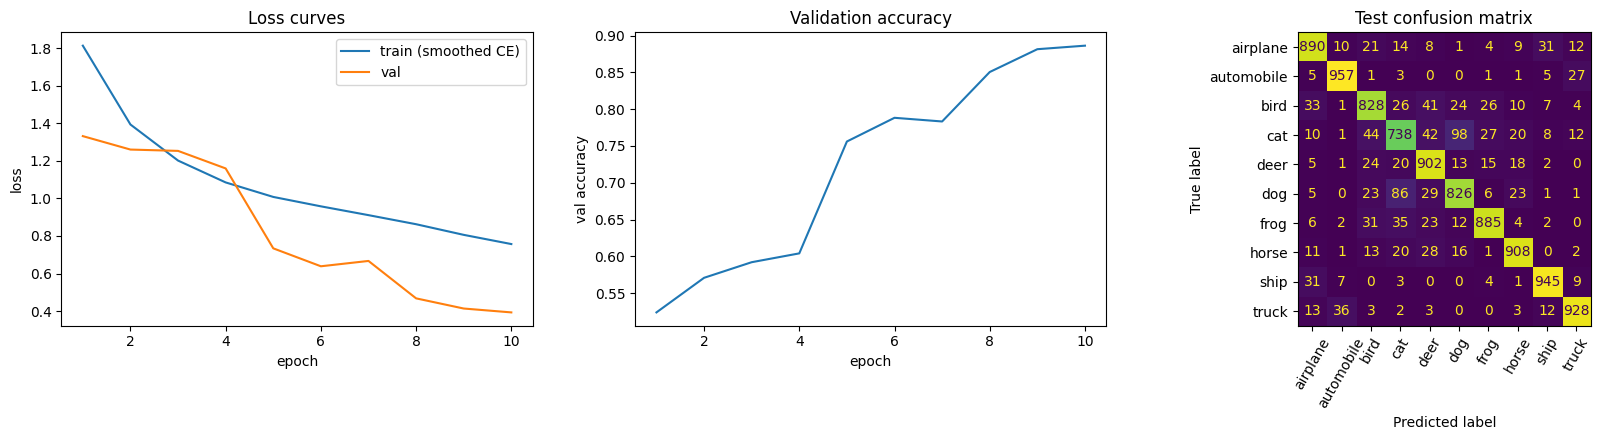

Per-class test accuracy (worst first):
cat           0.738
dog           0.826
bird          0.828
frog          0.885
airplane      0.890
deer          0.902
horse         0.908
truck         0.928
ship          0.945
automobile    0.957


In [9]:
h = pd.DataFrame(base["history"])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].plot(h.epoch, h.train_loss, label="train (smoothed CE)"); ax[0].plot(h.epoch, h.val_loss, label="val")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].set_title("Loss curves"); ax[0].legend()

ax[1].plot(h.epoch, h.val_acc); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("val accuracy"); ax[1].set_title("Validation accuracy")

ConfusionMatrixDisplay(confusion_matrix(base["labels"], base["preds"]), display_labels=CLASSES).plot(
    ax=ax[2], xticks_rotation=60, colorbar=False)
ax[2].set_title("Test confusion matrix")
plt.tight_layout(); plt.savefig("baseline_plots.png", dpi=150); plt.show()

# Per-class accuracy = where the model is weak
cm = confusion_matrix(base["labels"], base["preds"])
per_class = pd.Series(cm.diagonal() / cm.sum(1), index=CLASSES).sort_values()
print("Per-class test accuracy (worst first):"); print(per_class.round(3).to_string())

## 5. Ablation study
**Hypotheses (each one falsifiable):**
- H1: removing augmentation increases overfitting (larger train/val gap, lower val accuracy).
- H2: removing the skip connections hurts, but only modestly at this shallow depth (see the depth experiment below).
- H3: label smoothing and weight decay each give a small gain; differences under ~0.3% are within seed noise.

Quick version: each config is run over 2 seeds for 5 epochs. Expect roughly 10 minutes on a T4. Raise `ABL_EPOCHS` and `SEEDS` for a more reliable study.

In [10]:
ABL_EPOCHS = 5
SEEDS = [0, 1]
CONFIGS = {
    "baseline":           {},
    "no_augmentation":    {"augment": False},
    "no_residual":        {"residual": False},
    "no_label_smoothing": {"ls": 0.0},
    "no_weight_decay":    {"wd": 0.0},
}

rows = []
for name, ov in CONFIGS.items():
    for s in SEEDS:
        r = run(verbose=False, epochs=ABL_EPOCHS, seed=s, **ov)
        gap = r["history"][-1]["train_loss"] - r["history"][-1]["val_loss"]
        rows.append(dict(config=name, seed=s, val_acc=r["best_val"], test_acc=r["test_acc"]))
        print(f"{name:20s} seed={s} | val {r['best_val']:.4f} | test {r['test_acc']:.4f}")
        del r; torch.cuda.empty_cache()

df = pd.DataFrame(rows); df.to_csv("ablation_raw.csv", index=False)

baseline             seed=0 | val 0.8302 | test 0.8334
baseline             seed=1 | val 0.8340 | test 0.8384
no_augmentation      seed=0 | val 0.8420 | test 0.8397
no_augmentation      seed=1 | val 0.8512 | test 0.8419
no_residual          seed=0 | val 0.8408 | test 0.8335
no_residual          seed=1 | val 0.8322 | test 0.8361
no_label_smoothing   seed=0 | val 0.8356 | test 0.8342
no_label_smoothing   seed=1 | val 0.8348 | test 0.8332
no_weight_decay      seed=0 | val 0.8210 | test 0.8141
no_weight_decay      seed=1 | val 0.8266 | test 0.8245


                    val %  val std  test %  test std  Δ val vs baseline
config                                                                 
no_augmentation     84.66     0.65   84.08      0.16               1.45
no_residual         83.65     0.61   83.48      0.18               0.44
no_label_smoothing  83.52     0.06   83.37      0.07               0.31
baseline            83.21     0.27   83.59      0.35               0.00
no_weight_decay     82.38     0.40   81.93      0.74              -0.83


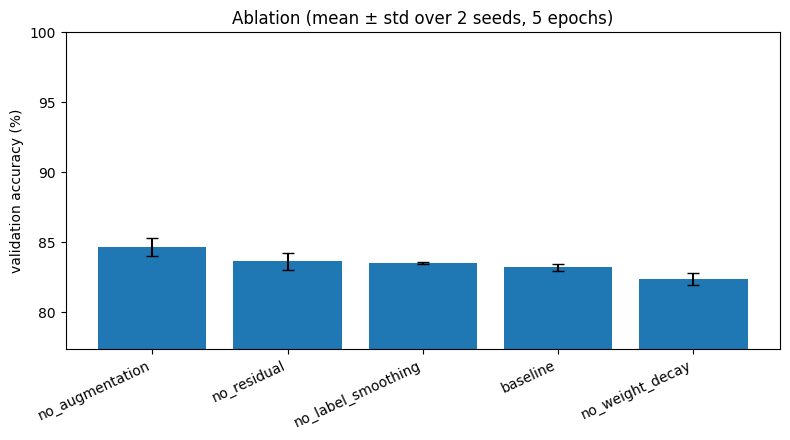

In [11]:
summary = df.groupby("config").agg(
    val_mean=("val_acc", "mean"), val_std=("val_acc", "std"),
    test_mean=("test_acc", "mean"), test_std=("test_acc", "std")).sort_values("val_mean", ascending=False)
base_val = summary.loc["baseline", "val_mean"]
summary["delta_vs_baseline_val"] = summary["val_mean"] - base_val

pretty = (summary * 100).round(2)
pretty.columns = ["val %", "val std", "test %", "test std", "Δ val vs baseline"]
print(pretty.to_string())
pretty.to_csv("ablation_summary.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(summary.index, summary.val_mean * 100, yerr=summary.val_std * 100, capsize=4)
ax.set_ylim(max(0, summary.val_mean.min() * 100 - 5), 100); ax.set_ylabel("validation accuracy (%)")
ax.set_title(f"Ablation (mean ± std over {len(SEEDS)} seeds, {ABL_EPOCHS} epochs)")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.savefig("ablation.png", dpi=150); plt.show()

## 6. (Optional) Depth stress test: when do skip connections really matter?
At 6 blocks the plain CNN still trains fine. Make it much deeper and the gap should widen, because gradients must traverse many more layers without the identity path. Set `RUN_DEPTH = True` to test this. It takes longer (about 3× per run).

In [12]:
RUN_DEPTH = False
if RUN_DEPTH:
    deep = {}
    for res in [True, False]:
        r = run(verbose=False, epochs=15, seed=0, blocks=(6, 6, 6), residual=res)
        deep[res] = r["best_val"]
        print(f"blocks=(6,6,6) residual={res}: val {r['best_val']:.4f}")
        del r; torch.cuda.empty_cache()
    print(f"Residual gain at depth 18 blocks: {(deep[True]-deep[False])*100:+.2f} pts")

## 7. Qualitative check + export

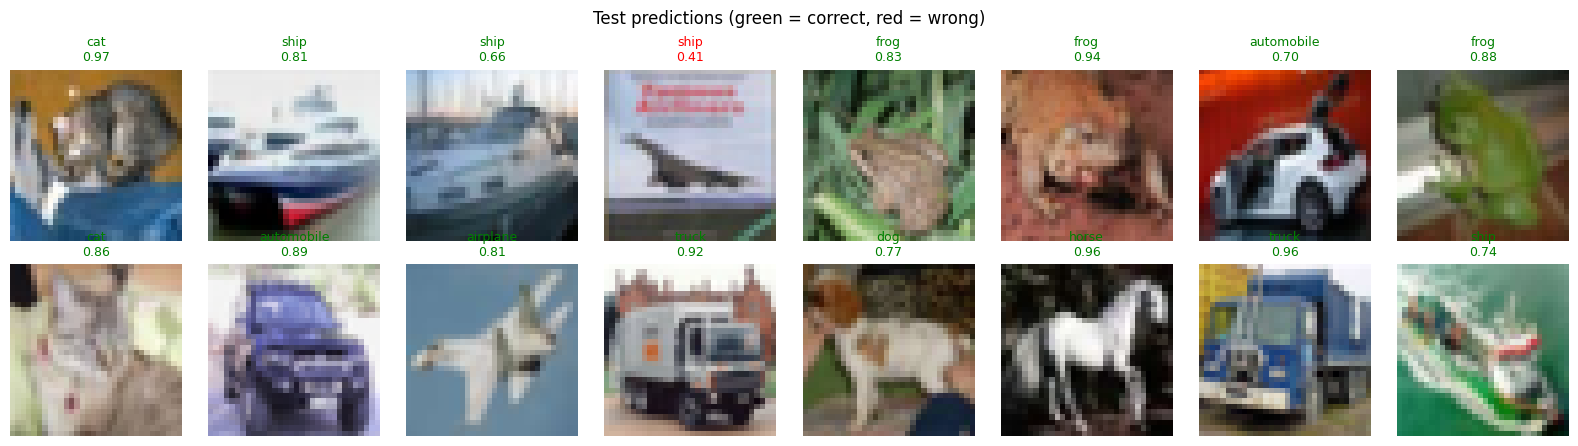

Saved: best.pt, baseline_results.json, baseline_plots.png, ablation.png, ablation_raw.csv, ablation_summary.csv, predictions.png


In [13]:
model = base["model"].eval()
_, _, test_dl = get_loaders(batch_size=16)
x, y = next(iter(test_dl))
with torch.no_grad():
    probs = model(x.to(device)).softmax(1).cpu()
conf, pred = probs.max(1)

mean = torch.tensor(MEAN).view(3, 1, 1); std = torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i, a in enumerate(axes.flat):
    a.imshow((x[i] * std + mean).clamp(0, 1).permute(1, 2, 0)); a.axis("off")
    ok = pred[i] == y[i]
    a.set_title(f"{CLASSES[pred[i]]}\n{conf[i]:.2f}", color="green" if ok else "red", fontsize=9)
plt.suptitle("Test predictions (green = correct, red = wrong)"); plt.tight_layout(); plt.savefig("predictions.png", dpi=150); plt.show()

torch.save(base["model"].state_dict(), "best.pt")
json.dump(dict(config={k: str(v) for k, v in base["cfg"].items()}, best_val_acc=base["best_val"],
               test_acc=base["test_acc"], history=base["history"]), open("baseline_results.json", "w"), indent=2)
print("Saved: best.pt, baseline_results.json, baseline_plots.png, ablation.png, ablation_raw.csv, ablation_summary.csv, predictions.png")

# Uncomment to download everything from Colab:
# from google.colab import files
# for f in ["best.pt", "baseline_results.json", "ablation_summary.csv", "ablation.png", "baseline_plots.png"]:
#     files.download(f)

## 8. Findings (fill in after you run this)
Replace the placeholders with your own measured numbers. Do not leave unfilled claims in a public repo.

| Question | Your result |
|---|---|
| Baseline val / test accuracy | |
| Which ablation hurt most? | |
| Which ablations were within noise (< ~0.3%)? | |
| Weakest classes (see per-class accuracy) | |
| Train/val gap without augmentation | |

**Known limitations**
- Quick settings: 10-epoch baseline, 5-epoch ablations, so absolute numbers are lower than a full 30-epoch run.
- 2 seeds give only a very rough noise estimate, not a significance test.
- Test accuracy is reported for every run but all decisions should be made on validation accuracy.

**Next steps:** wider/deeper nets, MixUp/CutMix, EMA of weights, test-time augmentation, ensembling across seeds.